# NN_L12_calibration

**Reliability diagram and expected calibration error of the label probabilities of zero-shot and few-shot Qwen2.5-3B and of TF-IDF with logistic regression on the Financial PhraseBank test set.**

Neural Networks and Deep Learning (NN), Lecture 12 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L12/NN_L12_calibration/NN_L12_calibration.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

ECE zs_3B (%) = 4.7   [calib.zs_3B]
ECE fs_3B (%) = 3.6   [calib.fs_3B_s0]
ECE tfidf (%) = 5.4   [calib.tfidf]


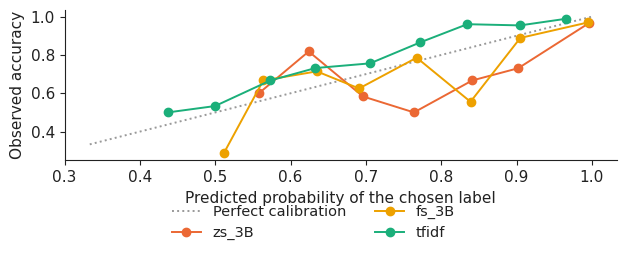

In [3]:
RES = REPO + 'lectures/L12/results/'
import json, urllib.request
def load_json(name):
    p = RES + name
    return json.load(open(p)) if os.path.exists(p) else json.load(urllib.request.urlopen(p))
from sklearn.metrics import f1_score, accuracy_score
LAB = {'pb': ['positive', 'negative', 'neutral'], 'tw': ['bullish', 'bearish', 'neutral']}
def f1(y, p, ds):
    return f1_score(y, p, labels=LAB[ds], average='macro')
def pred(df, m, ds):
    P = df[[f'{m}_{l}' for l in LAB[ds]]].values
    return [LAB[ds][i] for i in P.argmax(1)]
df = pd.read_csv(RES + 'predictions_pb.csv')
def rel(m, bins=10):
    P = df[[f'{m}_{l}' for l in LAB['pb']]].values
    conf = P.max(1)
    ok = np.array([LAB['pb'][i] == t for i, t in zip(P.argmax(1), df.label)])
    edges = np.linspace(1 / 3, 1, bins + 1)
    pts, ece = [], 0.0
    for a, b in zip(edges[:-1], edges[1:]):
        msk = (conf >= a) & (conf <= b if b == 1 else conf < b)
        if msk.sum() >= 5:
            pts.append((conf[msk].mean(), ok[msk].mean()))
        if msk.sum():
            ece += msk.mean() * abs(conf[msk].mean() - ok[msk].mean())
    return pts, ece
fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.plot([1 / 3, 1], [1 / 3, 1], ls=':', color='#999999', label='Perfect calibration')
for m, key, c in (('zs_3B', 'zs_3B', PAL['model']), ('fs_3B', 'fs_3B_s0', PAL['alt']), ('tfidf', 'tfidf', PAL['benchmark'])):
    pts, ece = rel(m)
    show(f'calib.{key}', f'ECE {m} (%)', round(100 * ece, 1))
    ax.plot([p[0] for p in pts], [p[1] for p in pts], marker='o', color=c, label=m)
ax.set_xlabel('Predicted probability of the chosen label')
ax.set_ylabel('Observed accuracy')
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('calibration.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()